# Esteira de aprendizado de máquina

Este notebook busca implementar uma esteira completa para machine learning, da preparação dos dados à avaliação do modelo

Fonte dos dados: https://archive.ics.uci.edu/dataset/544/estimation+of+obesity+levels+based+on+eating+habits+and+physical+condition

***
# Importando e caregando os dados

In [2]:
import pandas as pd
import zipfile as zf
import urllib.request as rq

# Baixando o zip
url = "https://archive.ics.uci.edu/static/public/544/estimation+of+obesity+levels+based+on+eating+habits+and+physical+condition.zip"
rq.urlretrieve(url, "estimation+of+obesity+levels+based+on+eating+habits+and+physical+condition.zip")

# Extraindo e carregando os dados
with zf.ZipFile("estimation+of+obesity+levels+based+on+eating+habits+and+physical+condition.zip", "r") as arquivo:
    arquivo.extract("ObesityDataSet_raw_and_data_sinthetic.csv")
df = pd.read_csv("ObesityDataSet_raw_and_data_sinthetic.csv", sep=",")



***
# Análise dos dados

In [3]:
print("Dimensões:", df.shape)
df.head()

Dimensões: (2111, 17)


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   object 
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   object 
 5   FAVC                            2111 non-null   object 
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   object 
 9   SMOKE                           2111 non-null   object 
 10  CH2O                            2111 non-null   float64
 11  SCC                             2111 non-null   object 
 12  FAF                             21

**Para maior claridade**

De acordo com a página do dataset:

* FAVC = Do you eat high caloric food frequently?
* FCVC = Do you usually eat vegetables in your meals?
* NCP = How many main meals do you have daily?
* CAEC = Do you eat any food between meals?
* SMOKE = Do you smoke?
* CH2O = How much water do you drink daily?
* SCC = Do you monitor the calories you eat daily?
* FAF = How often do you have physical activity?
* TUE = How much time do you use technological devices such as cell phone, videogames, television, computer and others?
* CALC = How often do you drink alcohol?
* MTRANS = Which transportation do you usually use?
* NObeyesdad = Obesity level **(ALVO)**




In [5]:
df.describe(include="all")

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
count,2111,2111.000000,2111.000000,2111.000000,2111,2111,2111.000000,2111.000000,2111,2111,2111.000000,2111,2111.000000,2111.000000,2111,2111,2111
unique,2,NaN,NaN,NaN,2,2,NaN,NaN,4,2,NaN,2,NaN,NaN,4,5,7
top,Male,NaN,NaN,NaN,yes,yes,NaN,NaN,Sometimes,no,NaN,no,NaN,NaN,Sometimes,Public_Transportation,Obesity_Type_I
freq,1068,NaN,NaN,NaN,1726,1866,NaN,NaN,1765,2067,NaN,2015,NaN,NaN,1401,1580,351
mean,NaN,24.312600,1.701677,86.586058,NaN,NaN,2.419043,2.685628,NaN,NaN,2.008011,NaN,1.010298,0.657866,NaN,NaN,NaN
std,NaN,6.345968,0.093305,26.191172,NaN,NaN,0.533927,0.778039,NaN,NaN,0.612953,NaN,0.850592,0.608927,NaN,NaN,NaN
min,NaN,14.000000,1.450000,39.000000,NaN,NaN,1.000000,1.000000,NaN,NaN,1.000000,NaN,0.000000,0.000000,NaN,NaN,NaN
25%,NaN,19.947192,1.630000,65.473343,NaN,NaN,2.000000,2.658738,NaN,NaN,1.584812,NaN,0.124505,0.000000,NaN,NaN,NaN
50%,NaN,22.777890,1.700499,83.000000,NaN,NaN,2.385502,3.000000,NaN,NaN,2.000000,NaN,1.000000,0.625350,NaN,NaN,NaN
75%,NaN,26.000000,1.768464,107.430682,NaN,NaN,3.000000,3.000000,NaN,NaN,2.477420,NaN,1.666678,1.000000,NaN,NaN,NaN


In [6]:
print("Valores ausentes:")
print(df.isnull().sum())
print()

Valores ausentes:
Gender                            0
Age                               0
Height                            0
Weight                            0
family_history_with_overweight    0
FAVC                              0
FCVC                              0
NCP                               0
CAEC                              0
SMOKE                             0
CH2O                              0
SCC                               0
FAF                               0
TUE                               0
CALC                              0
MTRANS                            0
NObeyesdad                        0
dtype: int64



In [7]:
print("Registros duplicados:")
print(df.duplicated().sum())
print()

Registros duplicados:
24



In [8]:
for coluna in df.select_dtypes(include="object").columns:
    quantidade = (df[coluna] == "unknown").sum()

    if quantidade > 0:
        print(f"{coluna}: {quantidade} valores desconhecidos")


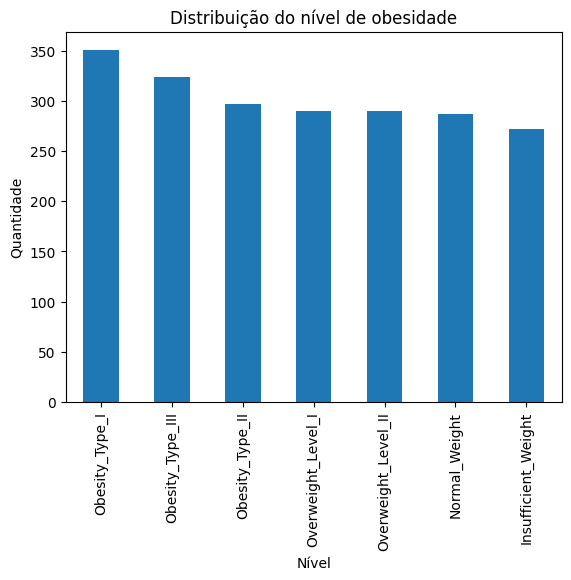

In [9]:
# Verificando distribuição da variável alvo
import matplotlib.pyplot as plt

df["NObeyesdad"].value_counts().plot(
    kind="bar",
    title="Distribuição do nível de obesidade",
    xlabel="Nível",
    ylabel="Quantidade"
)

plt.show()

In [10]:
# Frequência dos diferentes valores nas colunas categóricas
categoricas = df.select_dtypes(include="object").columns

for coluna in categoricas:
    print(df[coluna].value_counts())
    print("") # Linha vazia para não ficar tudo junto

Gender
Male      1068
Female    1043
Name: count, dtype: int64

family_history_with_overweight
yes    1726
no      385
Name: count, dtype: int64

FAVC
yes    1866
no      245
Name: count, dtype: int64

CAEC
Sometimes     1765
Frequently     242
Always          53
no              51
Name: count, dtype: int64

SMOKE
no     2067
yes      44
Name: count, dtype: int64

SCC
no     2015
yes      96
Name: count, dtype: int64

CALC
Sometimes     1401
no             639
Frequently      70
Always           1
Name: count, dtype: int64

MTRANS
Public_Transportation    1580
Automobile                457
Walking                    56
Motorbike                  11
Bike                        7
Name: count, dtype: int64

NObeyesdad
Obesity_Type_I         351
Obesity_Type_III       324
Obesity_Type_II        297
Overweight_Level_I     290
Overweight_Level_II    290
Normal_Weight          287
Insufficient_Weight    272
Name: count, dtype: int64



### Sobre os dados
Pelo que foi visto na análise, o dataset contém ao todo 2111 registros, com 17 variáveis para cada registro, 8 delas numéricas e 9 categóricas.
O dataset não possuí nenhum valor nulo, nem desconhecido, mas possuí 24 registros duplicados

***
# Tratamento dos dados
Nesta etapa, os dados serão pré-processados para adequamento para o modelo. As alterações serão sobre uma cópia, para preservar os dados originais

In [11]:
dfc = df.copy()
print("Dimensões:", dfc.shape)
dfc.head()

Dimensões: (2111, 17)


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [25]:
print("Registros duplicados na original:")
print(df.duplicated().sum())
print("Linhas na original:")
print(len(df))
print()

# limpando duplicatas
dfc = dfc.drop_duplicates().reset_index(drop=True)
print("Linhas na cópia, após remover duplicatas:")
print(len(dfc))
print("Registros duplicados na cópia:")
print(dfc.duplicated().sum())

Registros duplicados na original:
24
Linhas na original:
2111
Linhas na cópia, após remover duplicatas:
2087
Registros duplicados na cópia:
0


In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.model_selection import train_test_split


#Separando alvo e variáveis
alvo = "NObeyesdad"
X = dfc.drop(columns=[alvo])
y = dfc[alvo]

# Colunas binárias, ordinais, nominais e numéricas
cols_bin = ["Gender", "family_history_with_overweight", "FAVC", "SMOKE", "SCC"]
cols_ord = ["CAEC", "CALC"]
cols_nom = ["MTRANS"]
cols_num = ["Age", "Height", "Weight", "FCVC", "NCP", "CH2O", "FAF", "TUE"]

# Categorias ordinais
cat_ord = [
    ["no", "Sometimes", "Frequently", "Always"],  # CAEC
    ["no", "Sometimes", "Frequently", "Always"],  # CALC
]

# Em ordem:
# transforma colunas binárias (como yes/no) em uma coluna numérica (0 ou 1)
# transforma categoricas com ordem em números inteiros (0, 1, 2...)
# transforma categoricas sem ordem em colunas indicadoras (0 ou 1) para cada categoria.
# deixa as numéricas como estão
pre_processador = ColumnTransformer(
    transformers=[
        (
            "bin",
            OneHotEncoder(drop="if_binary", handle_unknown="ignore"),
            cols_bin),
        (
            "ord",
            OrdinalEncoder(
                categories=cat_ord,
                handle_unknown="use_encoded_value",
                unknown_value=-1,
            ),
            cols_ord,
        ),
        (
            "nom",
            OneHotEncoder(handle_unknown="ignore"),
            cols_nom),
        (
            "num",
            "passthrough",
            cols_num),
    ]
)

# Divide os dados em treino (70%) e temporários (30%)
X_treino, X_temp, y_treino, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Divide os dados temporários em validação (15%) e teste (15%)
X_val, X_teste, y_val, y_teste = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Verificando os conjuntos
print("Treino:", X_treino.shape, y_treino.shape)
print("Validação:", X_val.shape, y_val.shape)
print("Teste:", X_teste.shape, y_teste.shape)

Treino: (1460, 16) (1460,)
Validação: (313, 16) (313,)
Teste: (314, 16) (314,)


***
# Treinando e avaliando o modelo

O algoritmo escolhido foi o Random Forest, pois lida bem com relações não lineares e interações entre hábitos alimentares, atividade física, peso e altura sem exigir normalização, além de tender menos ao overfitting.


In [28]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline


modelo_rf = Pipeline(
    steps=[
        ("preprocessamento", pre_processador),
        (
            "classificador",
            RandomForestClassifier(
                n_estimators=200,
                random_state=42,
                n_jobs=-1,
            ),
        ),
    ]
)

modelo_rf.fit(X_treino, y_treino)

pred_val = modelo_rf.predict(X_val)
acuracia_val = accuracy_score(y_val, pred_val)
print(f"Acurácia na Validação: {acuracia_val:.4f}")

pred_teste = modelo_rf.predict(X_teste)
acuracia_teste = accuracy_score(y_teste, pred_teste)
print(f"Acurácia no Teste:     {acuracia_teste:.4f}\n")

Acurácia na Validação: 0.9489
Acurácia no Teste:     0.9427



Matriz de confusão (Teste):
[[37  3  0  0  0  0  0]
 [ 1 38  0  0  0  2  1]
 [ 0  0 51  0  0  0  2]
 [ 0  0  1 44  0  0  0]
 [ 0  0  0  0 49  0  0]
 [ 0  3  1  0  0 36  1]
 [ 0  1  1  0  0  1 41]]


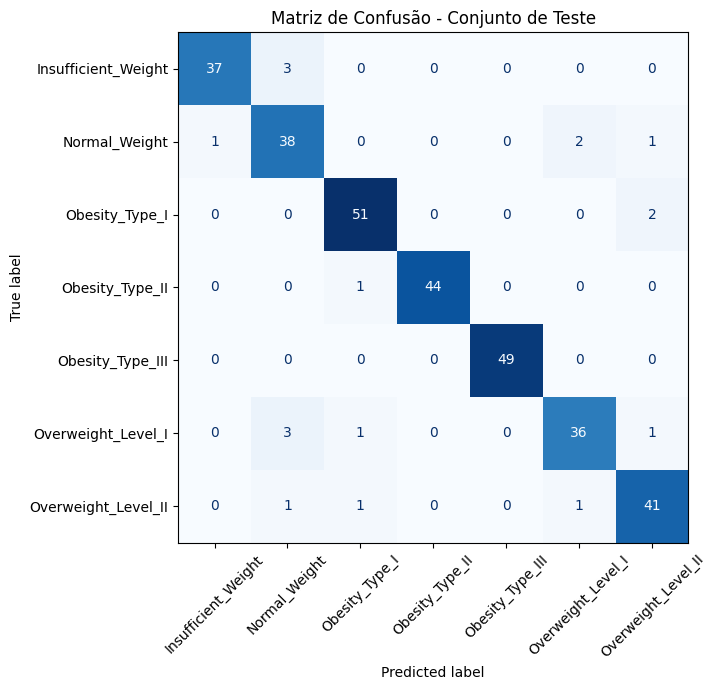

In [29]:
labels_ordenados = sorted(y.unique())
cm = confusion_matrix(y_teste, pred_teste, labels=labels_ordenados)

print("Matriz de confusão (Teste):")
print(cm)

fig, ax = plt.subplots(figsize=(9, 7))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels_ordenados)
disp.plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
plt.title("Matriz de Confusão - Conjunto de Teste")
plt.tight_layout()
plt.show()

In [30]:
exemplo_df = X_teste.iloc[[0]]
classe_real = y_teste.iloc[0]
classe_prevista = modelo_rf.predict(exemplo_df)[0]
probabilidades = modelo_rf.predict_proba(exemplo_df)[0]

print("\n--- Exemplo de Predição ---")
print(f"Classe real:     {classe_real}")
print(f"Classe prevista: {classe_prevista}")

# Mostra as 3 classes com maior probabilidade prevista
top_indices = probabilidades.argsort()[::-1][:3]
for idx in top_indices:
    print(f"  - {modelo_rf.classes_[idx]}: {probabilidades[idx]:.2%}")


--- Exemplo de Predição ---
Classe real:     Insufficient_Weight
Classe prevista: Insufficient_Weight
  - Insufficient_Weight: 93.50%
  - Overweight_Level_I: 3.00%
  - Normal_Weight: 2.50%
